In [22]:
import doodads as dd

In [23]:
dd.ref.sonora.diamondback.DIAMONDBACK_EVOLUTION_HYBRID

<DiamondbackEvolution: Sonora Diamondback (Morley 2024) (/Users/jlong/.local/share/doodads/data/generated/sonora_diamondback_2024_evolution.fits)>

In [24]:
dd.ref.sonora.diamondback.DIAMONDBACK_EVOLUTION_HYBRID.column_names

{'T_eff/K',
 'age/Gyr',
 'log(L/Lsun)',
 'log(g/cm/s^2)',
 'mass/Msun',
 'metallicity/[M/H]',
 'radius/Rsun'}

In [25]:
import astropy.units as u
raw_out = dd.DIAMONDBACK_EVOLUTION_HYBRID.interpolate(age=np.linspace(200, 1000) * u.Myr, mass=1.0 * u.Mjup)


k='age' _unitful_to_raw_mapping[k]=('age/Gyr', Unit("Gyr"))
k='mass' _unitful_to_raw_mapping[k]=('mass/Msun', Unit("solMass"))
k='metallicity' _unitful_to_raw_mapping[k]=('metallicity/[M/H]', Unit("dex"))


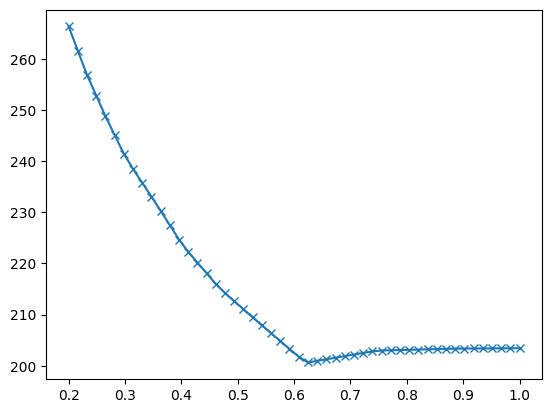

In [26]:
plt.plot(raw_out['age/Gyr'], raw_out['T_eff/K'], '-x')

In [27]:
dd.DIAMONDBACK_EVOLUTION_HYBRID.table

array([(2.0e-03, 0.0005, -5.7258,  538.72, 2.741, 1.536, -0.5),
       (2.0e-03, 0.001 , -5.1703,  752.09, 3.066, 1.494, -0.5),
       (2.0e-03, 0.0015, -4.8309,  914.87, 3.243, 1.492, -0.5), ...,
       (1.3e+01, 0.077 , -3.7098, 2099.03, 5.275, 1.03 ,  0.5),
       (1.3e+01, 0.078 , -3.6681, 2138.54, 5.271, 1.041,  0.5),
       (1.3e+01, 0.08  , -3.5893, 2214.92, 5.265, 1.063,  0.5)],
      shape=(8912,), dtype=[('age/Gyr', '<f4'), ('mass/Msun', '<f4'), ('log(L/Lsun)', '<f4'), ('T_eff/K', '<f4'), ('log(g/cm/s^2)', '<f4'), ('radius/Rsun', '<f4'), ('metallicity/[M/H]', '<f8')])

In [28]:
import re
import zipfile
import numpy as np

from doodads.ref.sonora.diamondback import parse_spectrum_filename, \
    _spectra_listing_to_params_table, _convert_spectra

# SPECTRUM_FN_RE = re.compile(r".*t(\d+)g(\d+)(f\d+|nc)_m([+-]?[\d.]+)_co([\d.]+).spec")

# def parse_spectrum_filename(fn_str, longest_fn_length=100):
#     res = SPECTRUM_FN_RE.match(fn_str)
#     if res is None:
#         raise RuntimeError(f"{fn_str=} did not parse")
#     temp, grav, fsed, met, co = res.groups()

#     row = np.array(
#         (
#             float(temp),
#             float(grav),
#             float(fsed[1:]) if fsed != "nc" else 0.0,
#             float(met),
#             float(co),
#         ),
#         [
#             ("name", f"S{longest_fn_length}"),
#             ("T_eff/K", float),
#             ("surface_grav/m/s^2", float),
#             ("f_sed", float),
#             ("metallicity/[M/H]", float),
#             ("[C/O]/solar [C/O]", float),
#         ],
#     )
#     return row


# def _spectra_listing_to_params_table(spectrum_files: list[str], longest_fn_length: int):
#     rows = np.asarray(
#         [
#             parse_spectrum_filename(x, longest_fn_length)
#             for x in spectrum_files
#             if x[-1] != "/"
#         ]
#     )
#     print(rows)
#     return rows

# def _convert_spectra(archive_filepath, output_filepath):
#     arch = zipfile.ZipFile(archive_filepath)
#     spectrum_files = arch.namelist()
#     longest_fn = max(len(x.rsplit("/", 1)[1]) for x in spectrum_files)
#     params = _spectra_listing_to_params_table(spectrum_files, longest_fn)
#     return params

In [29]:
input_path = '/Users/jlong/.local/share/doodads/data/downloads/73eab18c8e6ba65204e3ceaaede2f05944d99ae76ed7277fca1d72a91999cb64/spectra.zip'

In [31]:
_convert_spectra(input_path, None)

array([(b't900g1000f3_m-0.5_co1.0.spec',  900., 1000., 3., -0.5, 1.),
       (b't900g1000f8_m+0.5_co1.0.spec',  900., 1000., 8.,  0.5, 1.),
       (b't900g316f4_m-0.5_co1.0.spec',  900.,  316., 4., -0.5, 1.), ...,
       (b't2400g1000f1_m-0.5_co1.0.spec', 2400., 1000., 1., -0.5, 1.),
       (b't2400g1000f8_m0.0_co1.0.spec', 2400., 1000., 8.,  0. , 1.),
       (b't2400g316f8_m+0.5_co1.0.spec', 2400.,  316., 8.,  0.5, 1.)],
      shape=(1444,), dtype=[('name', 'S29'), ('T_eff/K', '<f8'), ('surface_grav/m/s^2', '<f8'), ('f_sed', '<f8'), ('metallicity/[M/H]', '<f8'), ('[C/O]/solar [C/O]', '<f8')])